=== Shape ===
Original (breast only): (1173, 21)
Extended:             (4173, 20)

=== Risk Level Distribution (proportions) ===
Original (breast only):
Risk_Level
Medium    0.802
Low       0.160
High      0.038
Name: proportion, dtype: float64

Extended:
Risk_Level
Medium    0.814
Low       0.152
High      0.034
Name: proportion, dtype: float64

Comparing 18 features

=== Statistical Comparison ===
Feature                    Orig Mean   Ext Mean    Orig SD     Ext SD
----------------------------------------------------------------------
Age                           62.939     62.893     10.733     10.946
Gender                         0.124      0.140      0.330      0.347
Smoking                        4.431      4.433      3.024      3.076
Alcohol_Use                    5.107      5.156      3.231      3.274
Obesity                        7.217      7.205      2.770      2.794
Family_History                 0.195      0.196      0.397      0.397
Diet_Red_Meat                  4.853

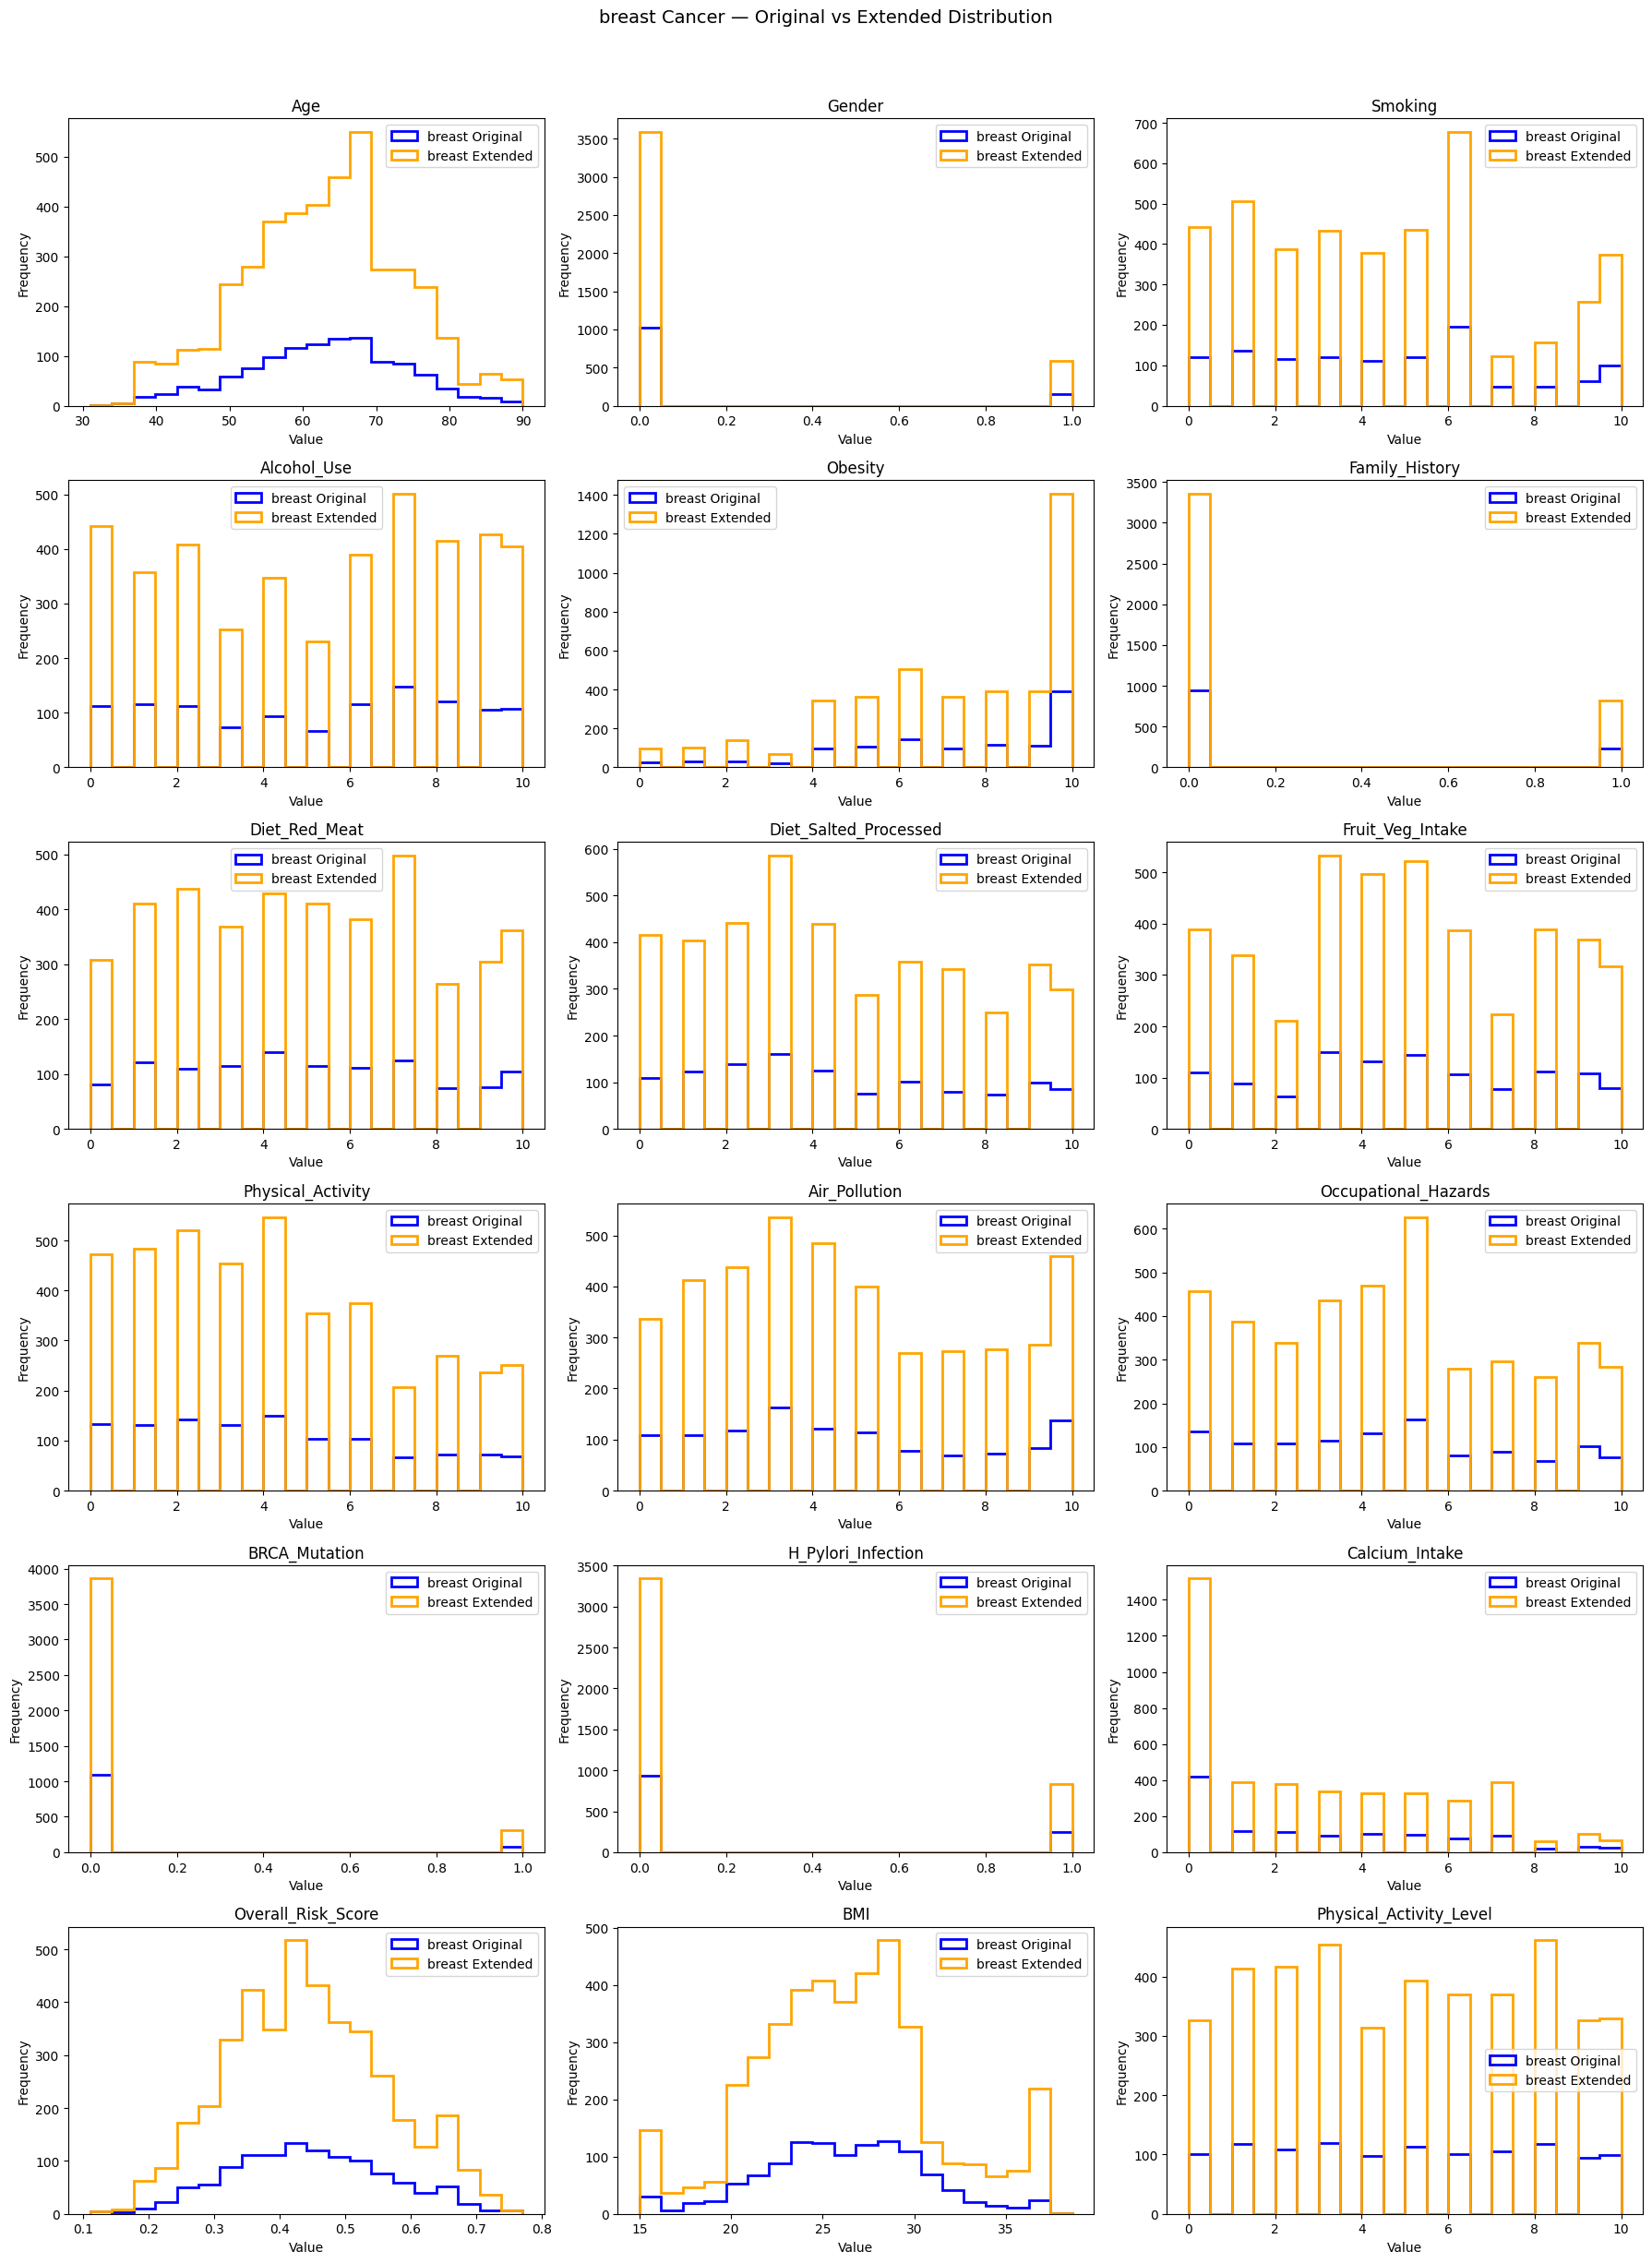

Saved breast_comparison.png


In [1]:
# Visual Representation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

# Load both
df_full = pd.read_csv("cancer-risk-factors-extended-1.csv")
df_breast_extended = pd.read_csv("breast_cancer_extended.csv")

# Filter original to breast only
df_original = df_full[df_full["Cancer_Type"] == "Breast"].copy()

print("=== Shape ===")
print(f"Original (breast only): {df_original.shape}")
print(f"Extended:             {df_breast_extended.shape}")

# Risk Level
print("\n=== Risk Level Distribution (proportions) ===")
print("Original (breast only):")
print(df_original["Risk_Level"].value_counts(normalize=True).round(3))
print("\nExtended:")
print(df_breast_extended["Risk_Level"].value_counts(normalize=True).round(3))

# Auto-detect numeric columns
exclude  = ["Patient_ID", "Cancer_Type", "Risk_Level"]
num_cols = [col for col in df_breast_extended.columns
            if col not in exclude]

print(f"\nComparing {len(num_cols)} features")

# Statistical comparison
print("\n=== Statistical Comparison ===")
print(f"{'Feature':<25} {'Orig Mean':>10} {'Ext Mean':>10} {'Orig SD':>10} {'Ext SD':>10}")
print("-" * 70)
for col in num_cols:
    print(f"{col:<25} "
          f"{df_original[col].mean():>10.3f} "
          f"{df_breast_extended[col].mean():>10.3f} "
          f"{df_original[col].std():>10.3f} "
          f"{df_breast_extended[col].std():>10.3f}")

# KS Test
print("\n=== KS Test (p > 0.05 = similar) ===")
for col in num_cols:
    stat, p = ks_2samp(df_original[col], df_breast_extended[col])
    status = "✓ similar" if p > 0.05 else "✗ different"
    print(f"{col:<25} p={p:.4f}  {status}")

# Histograms
n_cols_plot = 3
n_rows = int(np.ceil(len(num_cols) / n_cols_plot))

fig, axes = plt.subplots(n_rows, n_cols_plot, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    combined = pd.concat([df_original[col], df_breast_extended[col]])
    bins = np.linspace(combined.min(), combined.max(), 21)

    axes[i].hist(df_original[col], bins=bins, alpha=1.0,
                 color='blue', label='breast Original',
                 histtype='step', linewidth=2)
    axes[i].hist(df_breast_extended[col], bins=bins, alpha=1.0,
                 color='orange', label='breast Extended',
                 histtype='step', linewidth=2)
    axes[i].set_title(col)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")
    axes[i].legend()

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("breast Cancer — Original vs Extended Distribution",
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("breast_comparison.png", bbox_inches='tight', dpi=150)
plt.show()
print("Saved breast_comparison.png")